# Head model

We build an individual head model using a boundary element model (BEM). A BEM consists of all surfaces between the sources and the electrodes. They include the brain surface, inner skull, outer skull and skin. <br>
The brain surface was already computed during the FreeSurfer step. Here we compute the skull and skin surfaces.

## Imports

In [1]:
import mindmap as mm
import mne
import os
from pathlib import Path
import pyvista as pv

mm.io.read_config("../configurations/spike.yml", env=True)

## Data

In [2]:
# parameters
subject = "sub-pat09"
conductivities=[0.3, 0.006, 0.3]
min_skull_thick=2

# file
fs_dir = Path(os.environ["FS_DIR"])
bem_folder = fs_dir/subject/"bem"
if not bem_folder.exists():
    bem_folder.mkdir()

# plotting parameters
plot_bem_kwargs = dict(
    subject=subject,
    subjects_dir=fs_dir,
    brain_surfaces="white",
    orientation="coronal",
    slices=[50, 100, 150, 200]
)

## Create Surfaces from MRI
Run time: 5 min <br>
We use a watershed algorithm (2001).

In [3]:
mne.bem.make_watershed_bem(
    subject = subject,
    subjects_dir = os.environ["FS_DIR"],
    volume = "T1",
    overwrite = True,
)


Running mri_watershed for BEM segmentation with the following parameters:

Results dir = /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/bem/watershed
Command = mri_watershed -useSRAS -surf /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/bem/watershed/sub-pat09 /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/mri/T1.mgz /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/bem/watershed/ws.mgz

Running subprocess: mri_watershed -useSRAS -surf /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/bem/watershed/sub-pat09 /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/mri/T1.mgz /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/bem/watershed/ws.mgz

Mode:          use surfaceRAS to save surface vertex positions
Mode:   

Using surface: /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/bem/inner_skull.surf
Using surface: /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/bem/outer_skull.surf
Using surface: /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/bem/outer_skin.surf


/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/mne/viz/utils.py:167: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



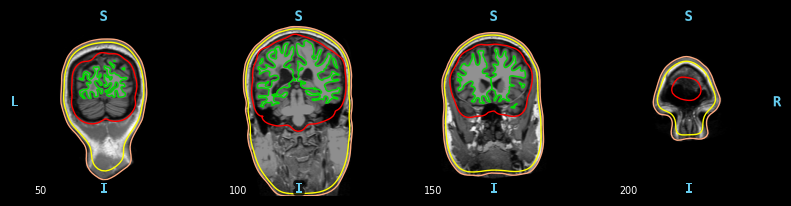

In [4]:
mne.viz.plot_bem(**plot_bem_kwargs)

## Correct Surfaces
The waterhsed algorithm sometimes generates an inner skull that goes outside the outer skull. We implemented some functions to correct for this.

In [5]:
from mindmap.utils.mri import correct_skull 

correct_skull(
    subject,
    offset = 2,
    fs_dir = fs_dir,
    save_arrows = True,
)

# Correct skull sends an "ERROR:root:No points/cells to operate on" when there are no 
# correction to be made. The program will continue without stopping.

ERROR:root:No points/cells to operate on
2024-09-23 08:09:26.989 ( 294.686s) [    7FA2DBEDA180]vtkIntersectionPolyData:2423  WARN| No Intersection between objects 
ERROR:root:No points/cells to operate on
2024-09-23 08:09:26.991 ( 294.689s) [    7FA2DBEDA180]vtkDistancePolyDataFilt:73     ERR| vtkDistancePolyDataFilter (0x21d20090): No points/cells to operate on
2024-09-23 08:09:26.993 ( 294.690s) [    7FA2DBEDA180]vtkDistancePolyDataFilt:73     ERR| vtkDistancePolyDataFilter (0x21d20090): No points/cells to operate on


Using surface: /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/bem/inner_skull.surf
Using surface: /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/bem/outer_skull.surf
Using surface: /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/sub-pat09/bem/outer_skin.surf


/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/mne/viz/utils.py:167: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



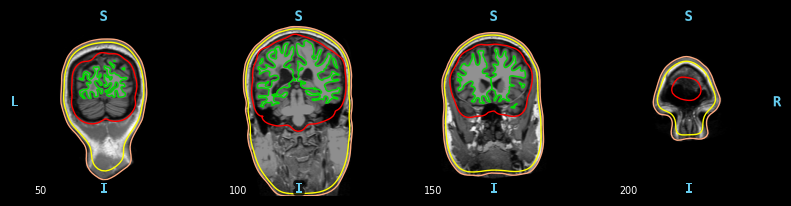

In [6]:
mne.viz.plot_bem(**plot_bem_kwargs)

## Create Boudary Element Model
In this section we apply some topological checks to verify if the surfaces are compatible with eachother in order to later make a conductor model.

# clean stuff
import pymeshfix
oskull_fname = f"../dataset/spike_sample/derivatives/freesurfer-7.4.1/{subject}/bem/outer_skull.surf" 
iskull_fname = f"../dataset/spike_sample/derivatives/freesurfer-7.4.1/{subject}/bem/inner_skull.surf" 

rr, tris = mne.read_surface(oskull_fname)
rr, tris = pymeshfix.clean_from_arrays(rr, tris)
mne.write_surface(oskull_fname, rr, tris, overwrite=True)

rr, tris = mne.read_surface(iskull_fname)
rr, tris = pymeshfix.clean_from_arrays(rr, tris)
mne.write_surface(iskull_fname, rr, tris, overwrite=True)

In [7]:
head_model = mne.make_bem_model(
        subject=subject,
        subjects_dir=fs_dir,
        conductivity=conductivities,
        #ico=None,
)

Creating the BEM geometry...
Going from 5th to 4th subdivision of an icosahedron (n_tri: 20480 -> 5120)
Going from 5th to 4th subdivision of an icosahedron (n_tri: 20480 -> 5120)
Going from 5th to 4th subdivision of an icosahedron (n_tri: 20480 -> 5120)
outer skin  CM is  -0.33 -15.81  16.22 mm
outer skull CM is  -0.30 -15.77  15.79 mm
inner skull CM is  -0.80 -19.04  26.66 mm
Checking that surface outer skull is inside surface outer skin  ...
Checking that surface inner skull is inside surface outer skull ...
Checking distance between outer skin  and outer skull surfaces...
Minimum distance between the outer skin  and outer skull surfaces is approximately    2.2 mm
Checking distance between outer skull and inner skull surfaces...
Minimum distance between the outer skull and inner skull surfaces is approximately    3.8 mm
Surfaces passed the basic topology checks.
Complete.



In [ ]:
colors = ["blue", "red", "yellow"]
opacities = [0.5, 0.5, 0.7]

surfaces = [mm.utils.surf_to_polydata(surf["rr"], surf["tris"]) for surf in head_model]

plotter = pv.Plotter()
for i, surf in enumerate(surfaces):
    plotter.add_mesh(surf, color=colors[i], opacity=opacities[i])

plotter.show()

Widget(value='<iframe src="http://localhost:34257/index.html?ui=P_0x7fa20ca444a0_0&reconnect=auto" class="pyvi…

ERROR:wslink.protocol:Exception raised
ERROR:wslink.protocol:ConnectionResetError('Cannot write to closing transport')
ERROR:wslink.protocol:Traceback (most recent call last):
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/wslink/protocol.py", line 317, in onCompleteMessage
    await self.sendWrappedMessage(
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/wslink/protocol.py", line 418, in sendWrappedMessage
    await ws.send_bytes(chunk)
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/aiohttp/web_ws.py", line 342, in send_bytes
    await self._writer.send(data, binary=True, compress=compress)
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/aiohttp/http_websocket.py", line 727, in send
    await self._send_frame(message, WSMsgType.BINARY, compress)
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/aiohttp/http_websocket.py", line 682, in _send_frame
    self._write

## Save Head Model

In [9]:
# save source space
folder = Path(os.environ["MM_DIR"])/subject/"fwd"

if folder.exists() == False:
        folder.mkdir(parents=True)

print(f"Saving head model for subject: {subject}")
mne.write_bem_surfaces(folder/f"{subject}_hm-bem.fif", head_model, overwrite=True)

Saving head model for subject: sub-pat09
Overwriting existing file.
